# CÀI ĐẶT THUẬT TOÁN

In [ ]:
class LogisticRegressionNumpy:
    def __init__(self, lr=0.01, epochs=1000):
        self.lr = lr
        self.epochs = epochs
        self.w = None
        self.b = None
        self.loss_history = []

    def _sigmoid(self, z):
        return 1.0 / (1.0 + np.exp(-np.clip(z, -250, 250)))

    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.w = np.zeros(n_features)
        self.b = 0.0
        self.loss_history = []

        for _ in range(self.epochs):
            y_pred = self._sigmoid(np.dot(X, self.w) + self.b)
            eps = 1e-15
            y_pred_clipped = np.clip(y_pred, eps, 1 - eps)
            loss = -np.mean(y * np.log(y_pred_clipped) + (1 - y) * np.log(1 - y_pred_clipped))
            self.loss_history.append(loss)
            dw = (1 / n_samples) * np.dot(X.T, (y_pred - y))
            db = (1 / n_samples) * np.sum(y_pred - y)
            self.w -= self.lr * dw
            self.b -= self.lr * db

    def predict(self, X, threshold=0.5):
        y_prob = self._sigmoid(np.dot(X, self.w) + self.b)
        return (y_prob >= threshold).astype(int)

def evaluate_binary(y_true, y_pred):
    tp = np.sum((y_true == 1) & (y_pred == 1))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0
    return precision, recall, f1

# HUẤN LUYỆN MÔ HÌNH


In [13]:
import numpy as np
import pandas as pd

DATA_PATH = "../../Lab01/2/sp500_yahoo.csv"
df = pd.read_csv(DATA_PATH)
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date').reset_index(drop=True)

df['Return'] = df['Close'].pct_change()
df['Vol_5d'] = df['Return'].rolling(5).std()
df['MA5_ratio'] = df['Close'] / df['Close'].rolling(5).mean() - 1
df['MA20_ratio'] = df['Close'] / df['Close'].rolling(20).mean() - 1
df['Volume_change'] = df['Volume'].pct_change()

df['Next_Return'] = df['Return'].shift(-1)
df = df.replace([np.inf, -np.inf], np.nan).dropna().reset_index(drop=True)
df['Target_Binary'] = (df['Next_Return'] > 0).astype(int)

feature_cols = ['Return', 'Vol_5d', 'MA5_ratio', 'MA20_ratio', 'Volume_change']
X = df[feature_cols].values
X = (X - X.mean(axis=0)) / X.std(axis=0)

split_idx = int(len(X) * 0.8)
X_train, X_test = X[:split_idx], X[split_idx:]
y_bin_train, y_bin_test = df['Target_Binary'].values[:split_idx], df['Target_Binary'].values[split_idx:]

model_bin = LogisticRegressionNumpy(lr=0.05, epochs=1000)
model_bin.fit(X_train, y_bin_train)

y_pred_bin = model_bin.predict(X_test, threshold=0.5)
prec, rec, f1 = evaluate_binary(y_bin_test, y_pred_bin)
acc = np.mean(y_bin_test == y_pred_bin)

print("=" * 50)
print(f"KẾT QUẢ ĐÁNH GIÁ (Bài 1 - Hồi quy Logistic):")
print(f"- Accuracy  : {acc:.4f}")
print(f"- Precision : {prec:.4f}")
print(f"- Recall    : {rec:.4f}")
print(f"- F1-Score  : {f1:.4f}")
print("=" * 50)

KẾT QUẢ ĐÁNH GIÁ (Bài 1 - Hồi quy Logistic):
- Accuracy  : 0.5338
- Precision : 0.5428
- Recall    : 0.8921
- F1-Score  : 0.6750


# VẼ ĐỒ THỊ

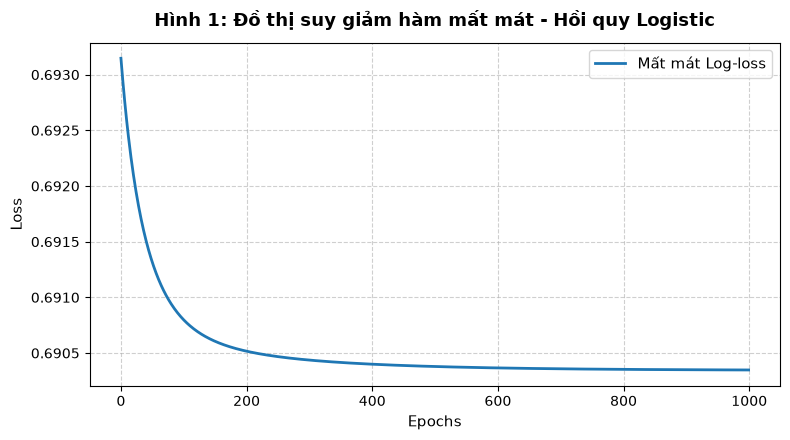

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4.5), dpi=100)
plt.plot(model_bin.loss_history, color='#1f77b4', linewidth=2, label='Mất mát Log-loss')

plt.title("Hình 1: Đồ thị suy giảm hàm mất mát - Hồi quy Logistic", fontsize=13, fontweight='bold', pad=12)
plt.xlabel("Epochs", fontsize=11)
plt.ylabel("Loss", fontsize=11)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()
